In [ ]:
import pandas as pd
import seaborn as sns
#Mostra todas as colunas do DataFrame
#Aumenta a largura de exibição no terminal
#Define um tamanho grande padrão para gráficos
def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})

In [ ]:
import json
#Leitura dos dados
def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T

In [ ]:
initialize_data_frame()
dungeon_frame = get_dungeon_data_frame()
user_frame = get_user_data_frame()

In [ ]:
print("DUNGEON DATA:")
print(dungeon_frame.head())

DUNGEON DATA:
                                                 PostFormAnswers TotalEnemies TotalMasteryQuests MaxCombo TotalExploreQuests TotalNpcs CompletedReportQuests CompletedListenQuests TotalDeaths CompletedAchievementQuests TotalGiveQuests TotalAchievementQuests TotalKeys    PlayerId TotalLocks KeysCollected TotalExchangeQuests TotalLostHealth CompletedExploreQuests CompletedExchangeQuests TotalGoToQuests RoomsEntered CompletedDamageQuests TotalAttempts TotalCreativityQuests TotalGatherQuests NpcsInteracted CompletedMasteryQuests                                       InputProfile CompletedGiveQuests WeaponName TotalImmersionQuests                                            HeatMap LocksOpened TotalReportQuests         LevelName TimeToFinish TotalTreasure TotalDamageQuests UniqueRoomsEntered TotalRooms CompletedCreativityQuests TreasuresCollected TotalQuests CompletedImmersionQuests CompletedGoToQuests CompletedGatherQuests TotalWins EnemiesKilled TotalListenQuests CompletedRead

In [ ]:
print("\nUSER DATA:")
print(user_frame.head())


USER DATA:
                                          GivenPlayerProfile                                      PlayerProfile TreasuresCollected TotalDamageQuests TotalReportQuests TotalGoToQuests TotalListenQuests CompletedDamageQuests CompletedCreativityQuests TotalDeaths TotalWins TotalReadQuests KeysCollected TotalExploreQuests CompletedListenQuests TotalEnemies UniqueRoomsEntered CompletedReadQuests TotalKeys RoomsEntered MaxCombo EnemiesKilled TotalLostHealth TotalMasteryQuests TotalGiveQuests CompletedAchievementQuests TotalExchangeQuests CompletedExchangeQuests CompletedGiveQuests CompletedReportQuests LocksOpened TotalGatherQuests CompletedGoToQuests CompletedImmersionQuests CompletedGatherQuests CompletedMasteryQuests TotalImmersionQuests CompletedKillQuests TotalCreativityQuests TotalQuests TotalNpcs NpcsInteracted   PlayerId TotalKillQuests TotalAchievementQuests CompletedExploreQuests TotalRooms CompletedQuests TotalAttempts PreFormAnswers TotalTreasure TotalLocks __collecti

In [ ]:
#Funções de limpeza dos dados
import numpy as np
def drop_invalid_rows(_data_frame): #remove quando o jogador nao acessou nenhuma sala
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame): #remove colunas que nao serao usadas
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame): #cria novas features tranfroamdno em porcentagem
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame): #remove as colunas usadas para criar porcentagem
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame

In [ ]:
dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
print("Após MERGE")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print(dungeon_frame.columns)
print("-"*80)

Após MERGE
(119, 57)
                     PostFormAnswers TotalEnemies TotalMasteryQuests MaxCombo TotalExploreQuests TotalNpcs CompletedReportQuests CompletedListenQuests TotalDeaths CompletedAchievementQuests TotalGiveQuests TotalAchievementQuests TotalKeys    PlayerId TotalLocks KeysCollected TotalExchangeQuests TotalLostHealth CompletedExploreQuests CompletedExchangeQuests TotalGoToQuests RoomsEntered CompletedDamageQuests TotalAttempts TotalCreativityQuests TotalGatherQuests NpcsInteracted CompletedMasteryQuests                                       InputProfile CompletedGiveQuests WeaponName TotalImmersionQuests                                            HeatMap LocksOpened TotalReportQuests         LevelName TimeToFinish TotalTreasure TotalDamageQuests UniqueRoomsEntered TotalRooms CompletedCreativityQuests TreasuresCollected TotalQuests CompletedImmersionQuests CompletedGoToQuests CompletedGatherQuests TotalWins EnemiesKilled TotalListenQuests CompletedReadQuests CompletedKillQ

In [ ]:
dungeon_frame = drop_invalid_rows(dungeon_frame)
print("Após drop_invalid_rows")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print("-"*80)

Após drop_invalid_rows
(119, 57)
                     PostFormAnswers TotalEnemies TotalMasteryQuests MaxCombo TotalExploreQuests TotalNpcs CompletedReportQuests CompletedListenQuests TotalDeaths CompletedAchievementQuests TotalGiveQuests TotalAchievementQuests TotalKeys    PlayerId TotalLocks KeysCollected TotalExchangeQuests TotalLostHealth CompletedExploreQuests CompletedExchangeQuests TotalGoToQuests RoomsEntered CompletedDamageQuests TotalAttempts TotalCreativityQuests TotalGatherQuests NpcsInteracted CompletedMasteryQuests                                       InputProfile CompletedGiveQuests WeaponName TotalImmersionQuests                                            HeatMap LocksOpened TotalReportQuests         LevelName TimeToFinish TotalTreasure TotalDamageQuests UniqueRoomsEntered TotalRooms CompletedCreativityQuests TreasuresCollected TotalQuests CompletedImmersionQuests CompletedGoToQuests CompletedGatherQuests TotalWins EnemiesKilled TotalListenQuests CompletedReadQuests Co

In [ ]:
dungeon_frame = drop_unused_columns(dungeon_frame)
print("Após drop_unused_columns")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print("-"*80)

Após drop_unused_columns
(119, 35)
                     PostFormAnswers TotalEnemies MaxCombo CompletedReportQuests CompletedListenQuests TotalDeaths CompletedAchievementQuests TotalKeys    PlayerId TotalLocks KeysCollected TotalLostHealth CompletedExploreQuests CompletedExchangeQuests RoomsEntered CompletedKillQuests TotalAttempts NpcsInteracted CompletedMasteryQuests                                       InputProfile CompletedGiveQuests LocksOpened         LevelName TimeToFinish TotalTreasure UniqueRoomsEntered TotalRooms CompletedCreativityQuests CompletedImmersionQuests CompletedGoToQuests CompletedGatherQuests TotalWins EnemiesKilled CompletedReadQuests PreFormAnswers
0  [4, 3, 4, 3, 4, 5, 5, 5, 4, 4, 4]            5        0                     0                     0           0                          0         4   102404526          4             4               6                      1                       0           53                   0             1              4     

In [ ]:
dungeon_frame = get_percentages(dungeon_frame)
print("Após get_percentages")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print("-"*80)

Após get_percentages
(119, 41)
                     PostFormAnswers  TotalEnemies  MaxCombo  CompletedReportQuests  CompletedListenQuests  TotalDeaths  CompletedAchievementQuests  TotalKeys    PlayerId  TotalLocks  KeysCollected  TotalLostHealth  CompletedExploreQuests  CompletedExchangeQuests  RoomsEntered  CompletedKillQuests  TotalAttempts  NpcsInteracted  CompletedMasteryQuests                                       InputProfile  CompletedGiveQuests  LocksOpened         LevelName  TimeToFinish  TotalTreasure  UniqueRoomsEntered  TotalRooms  CompletedCreativityQuests  CompletedImmersionQuests  CompletedGoToQuests  CompletedGatherQuests  TotalWins  EnemiesKilled  CompletedReadQuests PreFormAnswers  LockUsage  KeyCollection  MapCompletion  RoomRevisitRate  EnemyKillRate  Success Rate
0  [4, 3, 4, 3, 4, 5, 5, 5, 4, 4, 4]             5         0                      0                      0            0                           0          4   102404526           4              4        

/tmp/ipykernel_3801/115889845.py:31: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


In [ ]:
dungeon_frame = drop_processed_columns(dungeon_frame)
print("Após drop_processed_columns")
print(dungeon_frame.shape)
print(dungeon_frame.head())
print("-"*80)

Após drop_processed_columns
(119, 27)
                     PostFormAnswers  MaxCombo  CompletedReportQuests  CompletedListenQuests  CompletedAchievementQuests    PlayerId  TotalLostHealth  CompletedExploreQuests  CompletedExchangeQuests  CompletedKillQuests  CompletedMasteryQuests                                       InputProfile  CompletedGiveQuests         LevelName  TimeToFinish  CompletedCreativityQuests  CompletedImmersionQuests  CompletedGoToQuests  CompletedGatherQuests  CompletedReadQuests PreFormAnswers  LockUsage  KeyCollection  MapCompletion  RoomRevisitRate  EnemyKillRate  Success Rate
0  [4, 3, 4, 3, 4, 5, 5, 5, 4, 4, 4]         0                      0                      0                           0   102404526                6                       1                        0                    0                       0  {'AchievementPreference': 40, 'PlayerProfileEn...                    0  M:10T:20G:40E:30    415.995209                          1                    

In [ ]:
#Criar classe dos resultados
import os

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    kappa = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time

    def printCSV(self):
      # Cria a pasta se não existir
        os.makedirs("Classification", exist_ok=True)
        self.accuracy.to_csv('Classification/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv('Classification/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv('Classification/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv('Classification/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv('Classification/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv('Classification/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv('Classification/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv('Classification/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv('Classification/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv('Classification/classification_all_infer_time.csv', index=False, float_format='%.3f')

In [ ]:
import random

def split_preform_answers(_data_frame): #transforma os numeros em suas respectivas classes
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame

def augment_dataframe_with_scaling(df, y, n, scale_factor): #aumeto dos dados por escalonamento
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n): #versão sofisicad de data augmentation
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import time
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


# ==================================================
# Funções auxiliares
# ==================================================
def prepare_dataset(df): #preparação do dataset
    """
    Prepara o dataframe para modelagem:
    - Remove colunas irrelevantes
    - Reconstrói 'PreFormAnswers'
    - Separa os componentes A, C, I, M em colunas individuais
    """
    df = df.copy()

    # --------------------------------------------------
    # 1) Remoção de colunas não utilizadas
    # --------------------------------------------------
    print("Removendo colunas irrelevantes...")
    cols_to_drop = ['PostFormAnswers', 'PlayerId', 'InputProfile', 'LevelName']
    df.drop(columns=cols_to_drop, inplace=True)

    # --------------------------------------------------
    # 2) Reconstrução da string PreFormAnswers
    # --------------------------------------------------
    print("Reestruturando coluna PreFormAnswers...")
    df['PreFormAnswers'] = df['PreFormAnswers'].apply(
        lambda x: f"A={x[0]}, C={x[1]}, I={x[2]}, M={x[3]}"
    )

    df = split_preform_answers(df)

    return df

def generate_augmented_datasets(df):
    """
    Gera datasets aumentados usando ruído e escalonamento:
    - df_noise, df_scale_up, df_noise2, df_scale_both, df_mixed, df_mixed10
    - Retorna listas: dataframes, experiment_names, strategies
    """

    print("Gerando datasets com Data Augmentation...")
    n = df.shape[0]
    target_cols = ['PreFormAnswers', 'A', 'C', 'I', 'M']

    df_noise = augment_data_random(df, target_cols, n)
    df_scale_up = augment_dataframe_with_scaling(df, target_cols, n, 1.05)
    df_noise2 = augment_data_random(df, target_cols, 2*n)

    df_scale_both = pd.concat([
        augment_dataframe_with_scaling(df, target_cols, n, 1.05),
        augment_dataframe_with_scaling(df, target_cols, n, 0.95)
    ], ignore_index=True)

    df_mixed = pd.concat([
        augment_data_random(df, target_cols, n),
        augment_dataframe_with_scaling(df, target_cols, n, 1.05)
    ], ignore_index=True)

    df_mixed10 = pd.concat([
        augment_data_random(df, target_cols, 6*n),
        augment_dataframe_with_scaling(df, target_cols, n, 1.05),
        augment_dataframe_with_scaling(df, target_cols, n, 0.95),
        augment_dataframe_with_scaling(df, target_cols, n, 1.10),
        augment_dataframe_with_scaling(df, target_cols, n, 0.90)
    ], ignore_index=True)

    dataframes = [
        df,
        df_noise,
        df_scale_up,
        df_noise2,
        df_scale_both,
        df_mixed,
        df_mixed10
    ]

    experiment_names = [
        'Baseline',
        '1xNoise',
        '1xScaleUp',
        '2xNoise',
        '1xScaleDown',
        'Mixed',
        'HeavyMixed'
    ]

    strategies = [
        'Original',
        '1xNoise',
        '1xScale',
        '2xN',
        '2xScale',
        '1xN+1xS',
        '6xN+4xS'
    ]

    print("\nTamanhos dos datasets gerados:")
    print(f"Baseline: {len(df)}")
    print(f"1xNoise: {len(df_noise)}")
    print(f"1xScaleUp: {len(df_scale_up)}")
    print(f"2xNoise: {len(df_noise2)}")
    print(f"1xScaleDown (ScaleBoth): {len(df_scale_both)}")
    print(f"Mixed: {len(df_mixed)}")
    print(f"HeavyMixed: {len(df_mixed10)}")

    print("\nTamanhos dos datasets gerados:")
    print("\nQuantidade de dados NOVOS (comparado ao original):")
    print(f"1xNoise: {len(df_noise) - len(df)}")
    print(f"1xScaleUp: {len(df_scale_up) - len(df)}")
    print(f"2xNoise: {len(df_noise2) - len(df)}")
    print(f"1xScaleDown (ScaleBoth): {len(df_scale_both) - len(df)}")
    print(f"Mixed: {len(df_mixed) - len(df)}")
    print(f"HeavyMixed: {len(df_mixed10) - len(df)}")

    return dataframes, experiment_names, strategies

def prepare_train_test(df):
    """
    Gera datasets com diferentes estratégias de Data Augmentation
    Retorna listas: dataframes, experiment_names e strategies
    """
    profiles = df['PreFormAnswers']
    X = df.drop(columns=['PreFormAnswers', 'A', 'C', 'I', 'M', 'Success Rate'])

    print("Aplicando divisão Hold-out (70% treino / 30% teste)...")
    X_train, X_test, y_train, y_test = train_test_split(
        X, profiles, test_size=0.3, random_state=42
    )
    print(f"Tamanho treino: {X_train.shape[0]}")
    print(f"Tamanho teste: {X_test.shape[0]}")

    scaler = MinMaxScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    return X_train, X_test, y_train, y_test, X, profiles

def train_and_evaluate(model, X_train, X_test, y_train, y_test, X, y, experiment_name):
    """
    Prepara dados para treino e teste:
    - Separa features e target
    - Aplica Hold-Out 70/30
    - Normaliza as features
    """
    print(f"\nTreinando modelo: {model}")

    # ---------- Medir tempo de treino ----------
    start_train = time.perf_counter()
    model.fit(X_train, y_train)
    end_train = time.perf_counter()
    train_time = end_train - start_train
    print(f"Tempo de treino: {train_time:0.4f} segundos")

    # ---------- Medir tempo de inferência ----------
    start_pred = time.perf_counter()
    pred = model.predict(X_test)
    end_pred = time.perf_counter()
    infer_time = end_pred - start_pred
    print(f"Tempo de treino: {infer_time:0.4f} segundos")

    # ---------- Métricas Hold-Out ----------
    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred, average='weighted')
    rec = recall_score(y_test, pred, average='weighted')
    f1 = f1_score(y_test, pred, average='weighted')
    error_rate = 1 - acc
    kappa = cohen_kappa_score(y_test, pred)

    # ---------- Matriz de confusão ----------
    cm = confusion_matrix(y_test, pred)

    os.makedirs("Classification", exist_ok=True)

    with open("Classification/confusion_matrices.txt", "a") as f:
      f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
      f.write(str(cm))
      f.write("\n")

    print("\nMétricas Hold-Out:")
    print(f"Acurácia: {acc:.4f}")
    print(f"Precisão: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Taxa de erro: {error_rate:.4f}")
    print(f"Cohen Kappa: {kappa:.4f}")
    print(f"Tempo de treinamento: {train_time:.4f} seg")
    print(f"Tempo de inferência: {infer_time:.4f} seg")
    print("Matriz de Confusão:")
    print(cm)

    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=ax)

    plt.title("Confusion Matrix")
    plt.show()

    os.makedirs("Classification/images", exist_ok=True)

    plt.savefig(
        f"Classification/images/confusion_matrix_{experiment_name}_{model}.png",
        dpi=300,
        bbox_inches='tight'
    )

    #Validação cruzada
    cv_scores = cross_val_score(model, X, y, cv=5)

    return acc, prec, rec, f1, cv_scores.mean(), cv_scores.std()

def run_experiments(dataframes, experiment_names, models):
    """
    Treina o modelo e avalia métricas:
    - Hold-Out (acurácia, precisão, recall, F1)
    - Validação cruzada 5-fold
    """
    results = Results()

    # Aceita modelo único ou dicionário
    if not isinstance(models, dict):
        models = {'CustomModel': models}

    for model_name in models:
        results.addModel(model_name)

    for i, df in enumerate(dataframes):
        experiment_name = experiment_names[i]

        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]

        X_train, X_test, y_train, y_test, X, y = prepare_train_test(df)

        for model_name, model in models.items():
            print(f"\nExecutando modelo: {model_name} | Experimento: {experiment_name}")
            acc, prec, rec, f1, cv_m, cv_s = train_and_evaluate(
                model, X_train, X_test, y_train, y_test, X, y, experiment_name
            )

            accuracy.append(acc)
            precision.append(prec)
            recall.append(rec)
            f1score.append(f1)
            cv_mean.append(cv_m)
            cv_stddev.append(cv_s)
            kappa.append(kappa)
            error_rate.append(error_rate)
            train_time.append(train_time)
            infer_time.append(infer_time)

        results.addResults(accuracy, precision, recall, f1score, cv_mean, cv_stddev, kappa, error_rate, train_time, infer_time)



    results.printCSV()
    return results

In [ ]:
#from sklearn.naive_bayes import GaussianNB
#from sklearn.tree import DecisionTreeClassifier
#from sklearn import svm
#from sklearn.linear_model import SGDClassifier
#from sklearn.ensemble import HistGradientBoostingClassifier
#from tensorflow.keras.models import Sequential
#from tensorflow.keras.layers import LSTM, Dense

# ==================================================
# Função principal
# ==================================================
def classify(_df, models, verbose=True):
    """
    Função principal para classificar o dataset:
    - Prepara dataset
    - Gera estatísticas descritivas
    - Define modelos
    - Gera datasets aumentados
    - Executa experimentos
    """

    if _df.empty:
      raise ValueError("O dataframe está vazio!")
    if "PreFormAnswers" not in _df.columns:
        raise ValueError("A coluna 'PreFormAnswers' não está presente")

    print("\n================ INÍCIO DO PROCESSO ================\n")
    _df = _df.copy()   # <-- ISSO resolve o problema

    # Preparar o dataset
    _df = prepare_dataset(_df)

    # Tratamento de dados faltantes
    _df.dropna(inplace=True)

    # Estatísticas descritivas
    if verbose:
      print("Exportando estatísticas descritivas...")
    _df.describe().to_csv('descriptive_statistics.csv')

    # Definir modelo
    if verbose:
      print("Definindo modelo MLP...")

    # Gerar datasets aumentados
    dataframes, experiment_names, strategies = generate_augmented_datasets(_df)
    if verbose:
      print(f"{len(dataframes)} datasets gerados para experimentos.")

    # Executar experimentos
    run_experiments(dataframes, experiment_names, models)

    print("\n================ FIM DO PROCESSO ================\n")


In [ ]:
#TODO - Organizr o codigo acima, deixar certinho
#validar o mlp certinho dados tudo, depois ir pros outros modelos


================ INÍCIO DO PROCESSO ================

Removendo colunas irrelevantes...
Reestruturando coluna PreFormAnswers...
Exportando estatísticas descritivas...
Definindo modelo MLP...
Gerando datasets com Data Augmentation...

Tamanhos dos datasets gerados:
Baseline: 119
1xNoise: 238
1xScaleUp: 238
2xNoise: 357
1xScaleDown (ScaleBoth): 476
Mixed: 476
HeavyMixed: 1785

Tamanhos dos datasets gerados:

Quantidade de dados NOVOS (comparado ao original):
1xNoise: 119
1xScaleUp: 119
2xNoise: 238
1xScaleDown (ScaleBoth): 357
Mixed: 357
HeavyMixed: 1666
7 datasets gerados para experimentos.
Aplicando divisão Hold-out (70% treino / 30% teste)...
Tamanho treino: 83
Tamanho teste: 36

Executando modelo: Multilayer Perceptron | Experimento: Baseline

Treinando modelo: MLPClassifier(alpha=1e-05, hidden_layer_sizes=30, max_iter=500, random_state=42,
              solver='lbfgs')
Tempo de treino: 0.1850 segundos
Tempo de treino: 0.0006 segundos

Métricas Hold-Out:
Acurácia: 0.3056
Precisão: 0

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


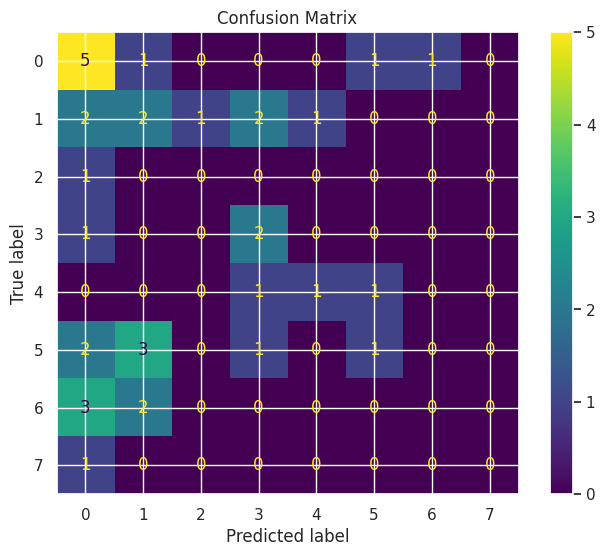

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.m

Aplicando divisão Hold-out (70% treino / 30% teste)...
Tamanho treino: 166
Tamanho teste: 72

Executando modelo: Multilayer Perceptron | Experimento: 1xNoise

Treinando modelo: MLPClassifier(alpha=1e-05, hidden_layer_sizes=30, max_iter=500, random_state=42,
              solver='lbfgs')
Tempo de treino: 0.3068 segundos
Tempo de treino: 0.0006 segundos

Métricas Hold-Out:
Acurácia: 0.5694
Precisão: 0.6071
Recall: 0.5694
F1-score: 0.5695
Taxa de erro: 0.4306
Cohen Kappa: 0.4852
Tempo de treinamento: 0.3068 seg
Tempo de inferência: 0.0006 seg
Matriz de Confusão:
[[ 8  0  0  0  0  4  3  0]
 [ 0 10  1  1  1  0  4  0]
 [ 1  0  1  0  0  0  2  0]
 [ 0  1  0  1  3  0  1  0]
 [ 2  0  0  0  3  1  0  0]
 [ 1  1  0  1  1 11  0  0]
 [ 1  0  0  0  1  0  6  0]
 [ 0  0  0  0  0  0  0  1]]


<Figure size 1920x1080 with 0 Axes>

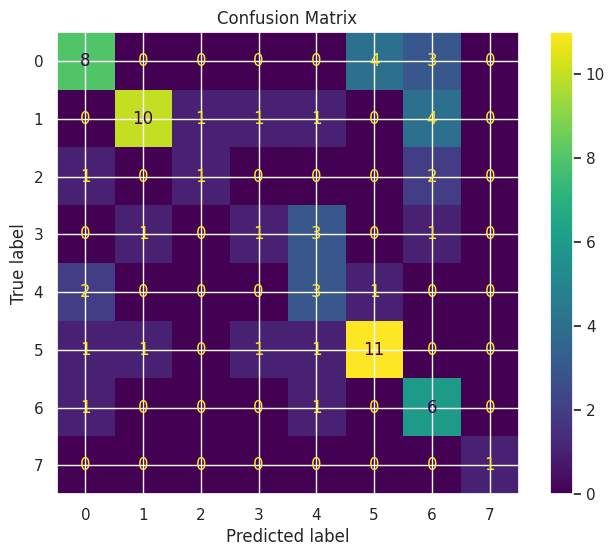

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS R

Aplicando divisão Hold-out (70% treino / 30% teste)...
Tamanho treino: 166
Tamanho teste: 72

Executando modelo: Multilayer Perceptron | Experimento: 1xScaleUp

Treinando modelo: MLPClassifier(alpha=1e-05, hidden_layer_sizes=30, max_iter=500, random_state=42,
              solver='lbfgs')
Tempo de treino: 0.1881 segundos
Tempo de treino: 0.0007 segundos

Métricas Hold-Out:
Acurácia: 0.7917
Precisão: 0.8406
Recall: 0.7917
F1-score: 0.7970
Taxa de erro: 0.2083
Cohen Kappa: 0.7490
Tempo de treinamento: 0.1881 seg
Tempo de inferência: 0.0007 seg
Matriz de Confusão:
[[10  0  0  0  1  2  1]
 [ 0 13  0  2  0  0  0]
 [ 1  0  2  0  0  0  0]
 [ 0  0  0  6  0  0  1]
 [ 0  0  0  0  6  0  0]
 [ 0  0  0  3  2 14  2]
 [ 0  0  0  0  0  0  6]]


<Figure size 1920x1080 with 0 Axes>

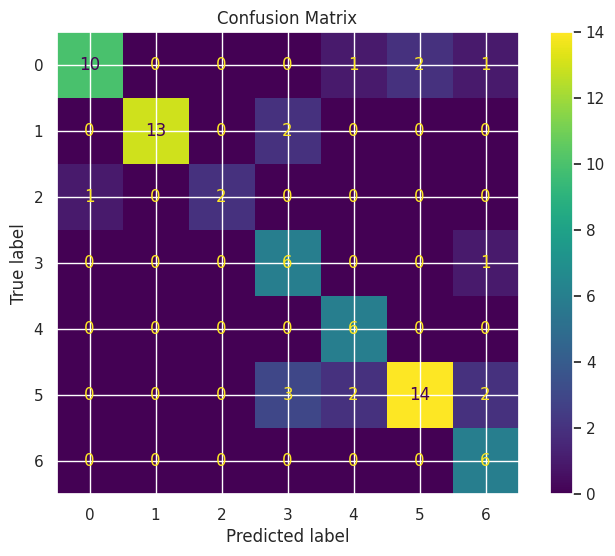

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.m

Aplicando divisão Hold-out (70% treino / 30% teste)...
Tamanho treino: 249
Tamanho teste: 108

Executando modelo: Multilayer Perceptron | Experimento: 2xNoise

Treinando modelo: MLPClassifier(alpha=1e-05, hidden_layer_sizes=30, max_iter=500, random_state=42,
              solver='lbfgs')
Tempo de treino: 0.4993 segundos
Tempo de treino: 0.0006 segundos

Métricas Hold-Out:
Acurácia: 0.5000
Precisão: 0.5059
Recall: 0.5000
F1-score: 0.4984
Taxa de erro: 0.5000
Cohen Kappa: 0.3990
Tempo de treinamento: 0.4993 seg
Tempo de inferência: 0.0006 seg
Matriz de Confusão:
[[13  1  1  2  2  4  2]
 [ 0  7  0  2  1  1  6]
 [ 1  2  2  0  0  2  0]
 [ 2  2  0 10  0  0  0]
 [ 0  0  0  1  4  2  0]
 [ 5  2  1  3  3 13  0]
 [ 1  3  1  0  0  1  5]]


<Figure size 1920x1080 with 0 Axes>

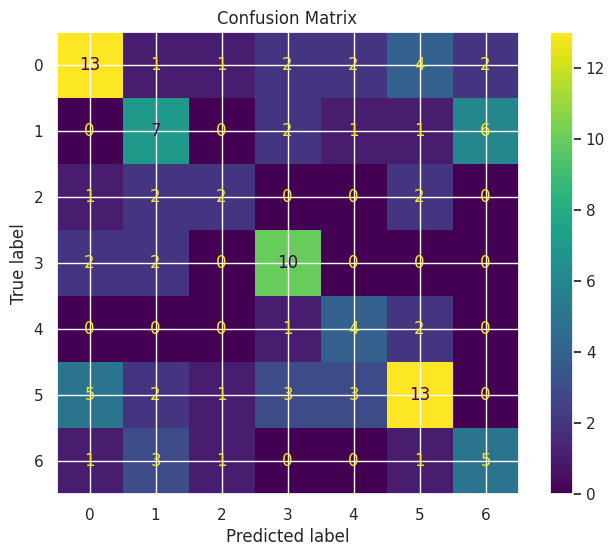

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.m

Aplicando divisão Hold-out (70% treino / 30% teste)...
Tamanho treino: 333
Tamanho teste: 143

Executando modelo: Multilayer Perceptron | Experimento: 1xScaleDown

Treinando modelo: MLPClassifier(alpha=1e-05, hidden_layer_sizes=30, max_iter=500, random_state=42,
              solver='lbfgs')
Tempo de treino: 0.3465 segundos
Tempo de treino: 0.0007 segundos

Métricas Hold-Out:
Acurácia: 0.9371
Precisão: 0.9435
Recall: 0.9371
F1-score: 0.9379
Taxa de erro: 0.0629
Cohen Kappa: 0.9225
Tempo de treinamento: 0.3465 seg
Tempo de inferência: 0.0007 seg
Matriz de Confusão:
[[37  0  0  0  0  2  0  0]
 [ 0 32  0  2  0  0  0  0]
 [ 0  0  7  0  0  0  0  0]
 [ 0  0  0 14  0  0  0  0]
 [ 0  0  0  0  7  0  0  0]
 [ 0  2  0  0  3 24  0  0]
 [ 0  0  0  0  0  0 12  0]
 [ 0  0  0  0  0  0  0  1]]


<Figure size 1920x1080 with 0 Axes>

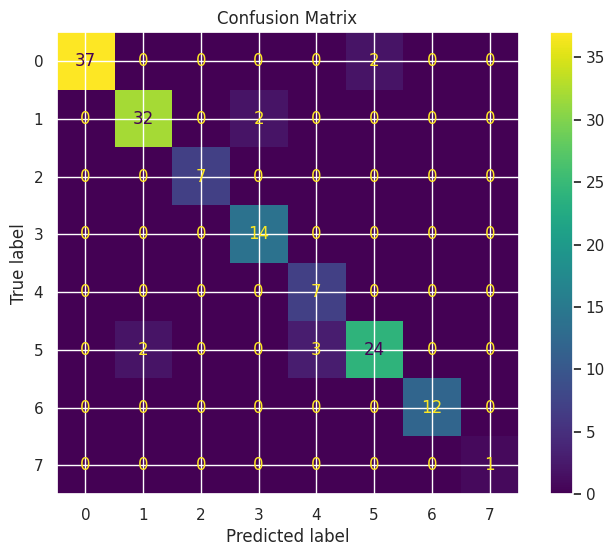

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.m

Aplicando divisão Hold-out (70% treino / 30% teste)...
Tamanho treino: 333
Tamanho teste: 143

Executando modelo: Multilayer Perceptron | Experimento: Mixed

Treinando modelo: MLPClassifier(alpha=1e-05, hidden_layer_sizes=30, max_iter=500, random_state=42,
              solver='lbfgs')
Tempo de treino: 0.2624 segundos
Tempo de treino: 0.0007 segundos

Métricas Hold-Out:
Acurácia: 0.8252
Precisão: 0.8326
Recall: 0.8252
F1-score: 0.8243
Taxa de erro: 0.1748
Cohen Kappa: 0.7878
Tempo de treinamento: 0.2624 seg
Tempo de inferência: 0.0007 seg
Matriz de Confusão:
[[34  1  0  0  0  0  3  0]
 [ 0 25  0  3  3  2  3  0]
 [ 0  0  8  0  0  0  0  0]
 [ 1  0  1 10  0  1  0  0]
 [ 2  0  0  0  8  0  0  0]
 [ 1  1  0  0  0 17  0  0]
 [ 0  1  0  0  0  2 15  0]
 [ 0  0  0  0  0  0  0  1]]


<Figure size 1920x1080 with 0 Axes>

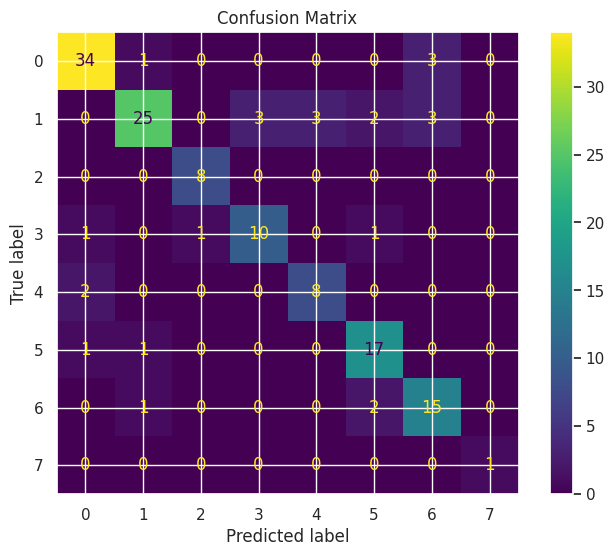

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.m

Aplicando divisão Hold-out (70% treino / 30% teste)...
Tamanho treino: 1249
Tamanho teste: 536

Executando modelo: Multilayer Perceptron | Experimento: HeavyMixed

Treinando modelo: MLPClassifier(alpha=1e-05, hidden_layer_sizes=30, max_iter=500, random_state=42,
              solver='lbfgs')


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


Tempo de treino: 6.2985 segundos
Tempo de treino: 0.0029 segundos

Métricas Hold-Out:
Acurácia: 0.9925
Precisão: 0.9926
Recall: 0.9925
F1-score: 0.9925
Taxa de erro: 0.0075
Cohen Kappa: 0.9910
Tempo de treinamento: 6.2985 seg
Tempo de inferência: 0.0029 seg
Matriz de Confusão:
[[112   0   0   0   0   0   0   0]
 [  1  93   0   0   0   0   0   0]
 [  0   0  32   0   0   0   0   0]
 [  0   0   0  48   0   0   0   0]
 [  0   1   0   0  44   0   0   0]
 [  0   0   0   0   0 117   0   0]
 [  1   1   0   0   0   0  83   0]
 [  0   0   0   0   0   0   0   3]]


<Figure size 1920x1080 with 0 Axes>

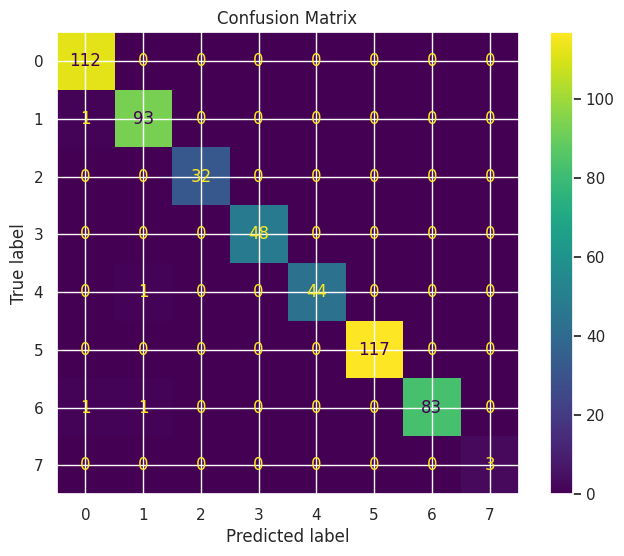

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS R


================ FIM DO PROCESSO ================



/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


<Figure size 1920x1080 with 0 Axes>

In [ ]:
models = {}
models['Multilayer Perceptron'] = MLPClassifier(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(30), random_state=42, max_iter=500)

#https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

classify(dungeon_frame, models, verbose=True)